<a href="https://colab.research.google.com/github/pcardel1205/PracticaTeachableMachine-PabloCarrascosa/blob/main/Pr%C3%A1ctica_1_TeachableMachine_PabloCarrascosaDelgado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MEMORIA DE PRÁCTICA: CLASIFICADOR DE IMÁGENES CON INTELIGENCIA ARTIFICIAL

1. ¿De qué trata esta práctica?

Para esta práctica el objetivo era montar una página web sencilla desde cero que sea capaz de reconocer imágenes utilizando inteligencia artificial. La idea principal era entrenar un modelo de forma rápida y luego integrarlo en local usando JavaScript para poder probarlo directamente en el navegador.

2. Cómo he entrenado el modelo

Lo primero que hice fue meterme en la web de Teachable Machine. Ahí creé un proyecto nuevo de imágenes y me puse a entrenar un par de categorías o clases distintas (un estuche y un teléfono). Para cada clase fui sacando fotos de prueba con la cámara para que la herramienta tuviera suficientes muestras. Una vez que el entrenamiento estuvo listo, le di a exportar el modelo marcando la opción de Tensorflow.js. Al descargarlo, te da una serie de archivos (model.json, el de los metadatos y los pesos) que simplemente hay que meter dentro de una carpeta llamada modelo en el proyecto.

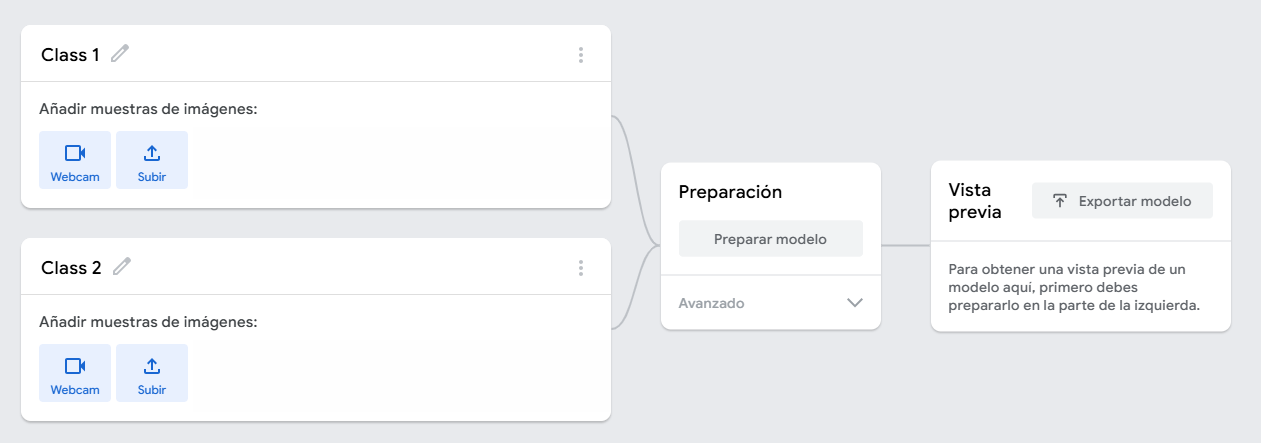
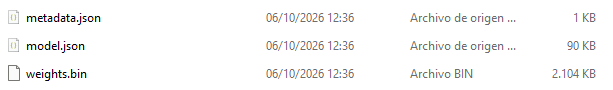

3. Organización y desarrollo de la web

Para que todo funcione en local organicé los archivos tal y como nos pedían:

index.html: Es la estructura básica de la página, donde puse un par de botones para elegir si quiero usar la cámara o subir una foto, además de los espacios para mostrar las imágenes y los resultados.

styles.css: Lo utilicé para darle un poco de diseño, centrar los elementos y que no se vea feo ni descolocado.

app.js: Es la parte de JavaScript. Aquí programé la carga del modelo al abrir la página y toda la lógica para que responda tanto al vídeo de la webcam como al archivo que suba el usuario.

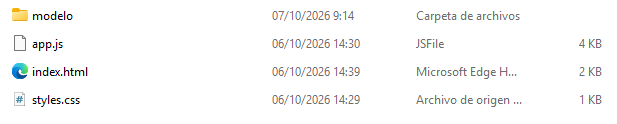

4. Implementación de las dos opciones (Cámara y Archivos)

Quise dejarlo preparado de forma que el usuario pueda elegir qué método usar en cada momento:

Usando la webcam: Si le das al botón de activar la cámara, el script arranca el streaming de vídeo y va leyendo fotograma a fotograma en un bucle continuo para lanzarle la predicción al modelo en tiempo real.

Subiendo una foto: Añadí un selector de archivos (input file) para que, si prefieres no usar la cámara, puedas buscar una foto en tu ordenador. Cuando la seleccionas, el código se encarga de detener la cámara si estaba abierta, leer la imagen mediante un FileReader, mostrarla en pantalla y pasarla al modelo para que te devuelva el resultado al instante.

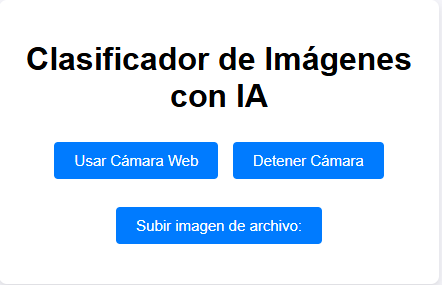
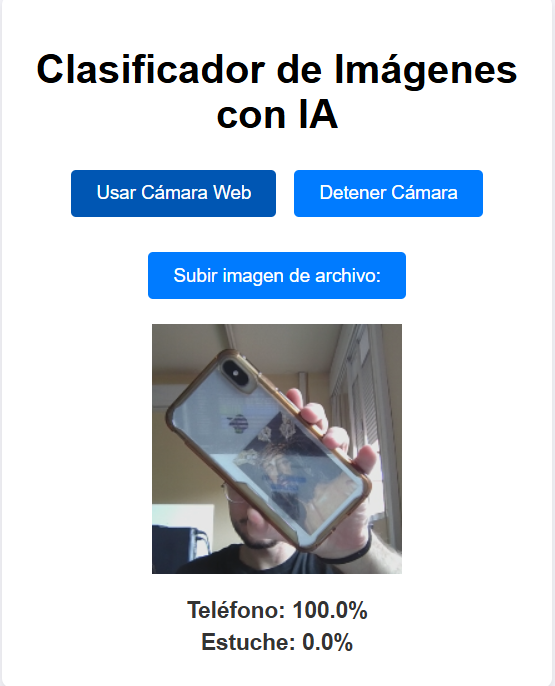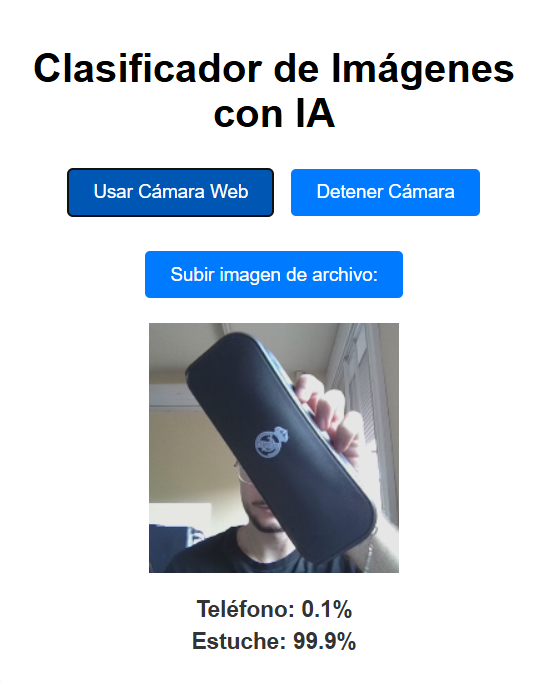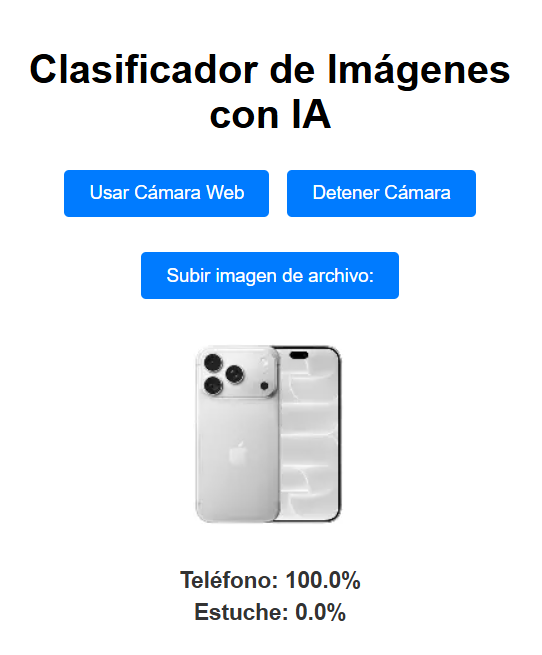

5. Conclusión

La verdad es que me ha parecido una práctica muy interesante porque demuestra lo fácil que es conectar un modelo de IA entrenado por ti mismo a una página web normal y corriente usando librerías como TensorFlow.js. Al final, dejarlo preparado para que funcione tanto en directo con la cámara como subiendo fotos desde el equipo le da mucha más versatilidad a la aplicación y cubre de sobra con lo que se pedía.

```
<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Clasificador Teachable Machine - Dual</title>
    <link rel="stylesheet" href="styles.css">
</head>
<body>
    <div class="container">
        <h1>Clasificador de Imágenes con IA</h1>
        
        <!-- Opciones de entrada -->
        <div class="controls">
            <button type="button" onclick="initWebcam()">Usar Cámara Web</button>
            <button type="button" onclick="stopWebcam()">Detener Cámara</button>
            <br><br>
            <label for="image-upload" class="file-upload-btn">Subir imagen de archivo:</label>
            <input type="file" id="image-upload" accept="image/*" onchange="predictFromFile(event)">
        </div>
        
        <!-- Contenedores para la cámara o la imagen subida -->
        <div id="webcam-container"></div>
        <div id="image-container">
            <img id="uploaded-image" src="" alt="" style="display:none; max-width: 200px; max-height: 200px; border-radius: 4px; margin: 10px auto;">
        </div>

        <!-- Resultados -->
        <div id="label-container"></div>
    </div>

    <!-- Librerías de TensorFlow.js y Teachable Machine Image -->
    <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.3.1/dist/tf.min.js"></script>
    <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8/dist/teachablemachine-image.min.js"></script>
    <script src="app.js"></script>
</body>
</html>
```

```
body {
    font-family: Arial, sans-serif;
    background-color: #f4f4f9;
    margin: 0;
    padding: 20px;
    display: flex;
    justify-content: center;
    text-align: center;
}

.container {
    background: white;
    padding: 20px;
    border-radius: 8px;
    box-shadow: 0 4px 8px rgba(0,0,0,0.1);
    max-width: 400px;
    width: 100%;
}

button, .file-upload-btn {
    padding: 10px 20px;
    font-size: 15px;
    background-color: #007bff;
    color: white;
    border: none;
    border-radius: 4px;
    cursor: pointer;
    display: inline-block;
    margin: 5px;
}

button:hover, .file-upload-btn:hover {
    background-color: #0056b3;
}

input[type="file"] {
    display: none; /* Ocultamos el input feo por defecto y usamos la etiqueta personalizada */
}

#webcam-container, #image-container {
    margin: 15px 0;
}

#label-container div {
    font-size: 18px;
    margin: 5px 0;
    font-weight: bold;
    color: #333;
}
```

```
const URL = "./modelo/";

let model, webcam, labelContainer, maxPredictions;
let isWebcamRunning = false;

// Cargar el modelo al iniciar la página para tenerlo listo
window.addEventListener('DOMContentLoaded', async () => {
    const modelURL = URL + "model.json";
    const metadataURL = URL + "metadata.json";

    try {
        model = await tmImage.load(modelURL, metadataURL);
        maxPredictions = model.getTotalClasses();
        
        labelContainer = document.getElementById("label-container");
        for (let i = 0; i < maxPredictions; i++) {
            labelContainer.appendChild(document.createElement("div"));
        }
        console.log("Modelo cargado correctamente.");
    } catch (error) {
        console.error("Error al cargar el modelo. Comprueba la ruta de la carpeta 'modelo'.", error);
    }
});

// --- OPCIÓN 1: CÁMARA WEB ---
async function initWebcam() {
    if (isWebcamRunning) return;
    
    // Si hay una imagen subida previamente, la ocultamos
    stopImageUpload();

    const flip = true;
    webcam = new tmImage.Webcam(200, 200, flip);
    await webcam.setup();
    await webcam.play();
    isWebcamRunning = true;
    
    window.requestAnimationFrame(webcamLoop);

    const webcamContainer = document.getElementById("webcam-container");
    webcamContainer.innerHTML = ""; // Limpiar por si acaso
    webcamContainer.appendChild(webcam.canvas);
}

async function webcamLoop() {
    if (!isWebcamRunning) return;
    webcam.update();
    await predict(webcam.canvas);
    window.requestAnimationFrame(webcamLoop);
}

function stopWebcam() {
    if (isWebcamRunning && webcam) {
        webcam.stop();
        isWebcamRunning = false;
        document.getElementById("webcam-container").innerHTML = "";
        clearLabels();
    }
}

// --- OPCIÓN 2: SUBIR IMAGEN DESDE ARCHIVOS ---
async function predictFromFile(event) {
    const file = event.target.files[0];
    if (!file) return;

    // Detenemos la cámara si estaba activa
    stopWebcam();

    const reader = new FileReader();
    reader.onload = function(e) {
        const imgElement = document.getElementById("uploaded-image");
        imgElement.src = e.target.result;
        imgElement.style.display = "block";

        // Una vez cargada en el DOM, realizamos la predicción
        imgElement.onload = async function() {
            await predict(imgElement);
        };
    };
    reader.readAsDataURL(file);
}

function stopImageUpload() {
    const imgElement = document.getElementById("uploaded-image");
    imgElement.src = "";
    imgElement.style.display = "none";
    document.getElementById("image-upload").value = "";
}

// --- FUNCIÓN GENÉRICA DE PREDICCIÓN ---
async function predict(sourceElement) {
    if (!model) return;
    
    // model.predict acepta elementos de tipo HTML (canvas, img, video)
    const prediction = await model.predict(sourceElement);
    
    for (let i = 0; i < maxPredictions; i++) {
        const classPrediction =
            prediction[i].className + ": " + (prediction[i].probability * 100).toFixed(1) + "%";
        labelContainer.childNodes[i].innerHTML = classPrediction;
    }
}

function clearLabels() {
    if (labelContainer) {
        for (let i = 0; i < labelContainer.childNodes.length; i++) {
            labelContainer.childNodes[i].innerHTML = "";
        }
    }
}
```